# Air Quality – Relative Humidity (RH) Regression


## 1. Import Libraries

In [ ]:
import os, glob, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Configuration  ✏️ (the only cell you normally edit)

| Setting | Meaning |
|---|---|
| `DATA_PATH` | Your data file: `.csv`, `.xlsx` or a `.zip` containing one. If not found, Colab asks you to upload it and Kaggle searches `/kaggle/input`. |
| `TARGET_COLUMN` | The column you want to predict (must be numeric). Set to `None` to let the notebook suggest one. |
| `DROP_COLUMNS` | Columns to ignore (e.g. `["id", "Name"]`). |
| `MISSING_MARKERS` | Numbers that secretly mean "missing" (Air Quality uses `-200`). Use `[]` if your data has none. |
| `MAX_MISSING_PCT` | Columns with more than this % missing values are dropped automatically (Air Quality's `NMHC(GT)` is ~90% missing). |
| `DATE_COL` / `TIME_COL` | Optional date/time columns. They are converted into `Month`, `DayOfWeek` and `Hour` features. Use `None` to skip. |
| `MODEL_NAME` | `"Linear Regression"` (straight-line fit) or `"Polynomial Regression"` (curved fit). |
| `POLY_DEGREE` | Degree of the polynomial (used only for Polynomial Regression). 2 = squares and pair products, 3 = cubes too. Higher = more flexible but easier to overfit. |
| `ENCODE_AS_CATEGORICAL` | Optional list of numeric columns that should be treated as categories and One-Hot encoded (e.g. `["DayOfWeek"]`). Default `[]` = none. |
| `OUTLIER_STRATEGY` | `"cap"` (limit extreme feature values, learned from training data only) or `"keep"` (leave as is). |

> ⚠️ **Why `AH` is dropped:** Absolute Humidity (AH) is calculated by a physical formula from Temperature (T) and Relative Humidity (RH). If `AH` is kept as a feature, the model can almost reverse the formula and the score looks unrealistically perfect (R² ≈ 0.99+). Removing it gives an honest result. To see the 'leaky' version, set `DROP_COLUMNS = []` in the cell below.

In [ ]:

DATA_PATH        = "AirQualityUCI.csv"    # also works with "air_quality.zip" or "AirQualityUCI.xlsx"
TARGET_COLUMN    = "RH"                 # Air Quality: "RH" (Relative Humidity) or "AH" (Absolute Humidity)
DROP_COLUMNS     = ["AH"]                # the other humidity column is removed on purpose (see note below)
MISSING_MARKERS  = [-200]                 # values that really mean "missing"
MAX_MISSING_PCT  = 40                     # drop columns with more than 40% missing values
DATE_COL         = "Date"                 # set to None if there is no date column
TIME_COL         = "Time"                 # set to None if there is no time column
MODEL_NAME       = "Polynomial Regression"   # "Linear Regression" or "Polynomial Regression"
POLY_DEGREE      = 3                         # only used for Polynomial Regression (try 2, 3, 4)
OUTLIER_STRATEGY = "cap"
ENCODE_AS_CATEGORICAL = []               # e.g. ["DayOfWeek"] -> treated as categories and One-Hot encoded

TEST_SIZE    = 0.2
RANDOM_STATE = 42

## 3. Load Dataset

In [ ]:
# --- Locate the file: local path -> Colab upload -> Kaggle input folder ---
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files          # only exists in Colab
        print("File not found. Please upload your CSV / XLSX / ZIP file:")
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        found = []
        for pattern in ("*.csv", "*.xlsx", "*.zip"):
            found += glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
        if len(found) == 0:
            raise FileNotFoundError(f"Could not find '{DATA_PATH}'. Check the file name or upload the file.")
        DATA_PATH = found[0]
        print("Using file found in Kaggle input:", DATA_PATH)

# --- If it is a ZIP, extract the first CSV/XLSX inside it ---
if DATA_PATH.lower().endswith(".zip"):
    with zipfile.ZipFile(DATA_PATH) as z:
        names = [n for n in z.namelist() if n.lower().endswith((".csv", ".xlsx")) and not n.startswith("__MACOSX")]
        if not names:
            raise ValueError("The ZIP file contains no .csv or .xlsx file.")
        names.sort(key=lambda n: (not n.lower().endswith(".csv"), n))   # prefer CSV
        z.extract(names[0], "extracted_data")
        DATA_PATH = os.path.join("extracted_data", names[0])
        print("Extracted from ZIP:", DATA_PATH)

# --- Read the file (auto-detects separator and decimal comma) ---
if DATA_PATH.lower().endswith(".xlsx"):
    df = pd.read_excel(DATA_PATH)
else:
    with open(DATA_PATH, "r", encoding="utf-8", errors="ignore") as f:
        header = f.readline()
    sep = max([",", ";", "\t", "|"], key=header.count)              # most common delimiter in the header line
    df = pd.read_csv(DATA_PATH, sep=sep, low_memory=False)
    # Decimal commas (e.g. "2,6"): text columns that look like numbers with a comma -> real numbers
    for col in df.select_dtypes(exclude="number").columns:
        s = df[col].dropna().astype(str)
        if len(s) and s.str.fullmatch(r"-?\d+,\d+").mean() > 0.5:
            df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    print(f"Separator detected: {sep!r}")

df.columns = df.columns.astype(str).str.strip()     # remove accidental spaces in column names

# --- Generic cleaning ---
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]   # empty trailing columns (extra ; at line ends)
df = df.dropna(how="all").reset_index(drop=True)        # completely blank rows

# Hidden missing values (e.g. -200 in Air Quality)
if MISSING_MARKERS:
    num_c = df.select_dtypes(include="number").columns
    df[num_c] = df[num_c].replace(MISSING_MARKERS, np.nan)

# Date / Time -> Month, DayOfWeek, Hour
if DATE_COL and DATE_COL in df.columns:
    d = pd.to_datetime(df[DATE_COL], dayfirst=True, errors="coerce")
    df["Month"], df["DayOfWeek"] = d.dt.month, d.dt.dayofweek
    df = df.drop(columns=[DATE_COL])
if TIME_COL and TIME_COL in df.columns:
    df["Hour"] = pd.to_numeric(df[TIME_COL].astype(str).str.extract(r"^(\d{1,2})")[0], errors="coerce")
    df = df.drop(columns=[TIME_COL])

# Columns with too many missing values
too_missing = [c for c in df.columns if c != TARGET_COLUMN and df[c].isnull().mean() * 100 > MAX_MISSING_PCT]
if too_missing:
    print(f"Dropping columns with more than {MAX_MISSING_PCT}% missing values:", too_missing)
    df = df.drop(columns=too_missing)

if DROP_COLUMNS:
    df = df.drop(columns=[c for c in DROP_COLUMNS if c in df.columns])

original_shape = df.shape

print("File loaded:", DATA_PATH)
print("Shape (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())
print("\nBasic statistics:")
display(df.describe().T)

File not found. Please upload your CSV / XLSX / ZIP file:


Saving AirQualityUCI.csv to AirQualityUCI.csv
Separator detected: ';'
Dropping columns with more than 40% missing values: ['NMHC(GT)']
File loaded: AirQualityUCI.csv
Shape (rows, columns): (9357, 14)

Column names: ['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'Month', 'DayOfWeek', 'Hour']

Data types:
CO(GT)           float64
PT08.S1(CO)      float64
C6H6(GT)         float64
PT08.S2(NMHC)    float64
NOx(GT)          float64
PT08.S3(NOx)     float64
NO2(GT)          float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
T                float64
RH               float64
Month              int32
DayOfWeek          int32
Hour               int64
dtype: object

First 5 rows:


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,Month,DayOfWeek,Hour
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,3,2,18
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,3,2,19
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,3,2,20
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,3,2,21
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,3,2,22



Basic statistics:


,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.152750,1.453252,0.1,1.1,1.8,2.9,11.9
PT08.S1(CO),8991.0,1099.833166,217.080037,647.0,937.0,1063.0,1231.0,2040.0
C6H6(GT),8991.0,10.083105,7.449820,0.1,4.4,8.2,14.0,63.7
PT08.S2(NMHC),8991.0,939.153376,266.831429,383.0,734.5,909.0,1116.0,2214.0
NOx(GT),7718.0,246.896735,212.979168,2.0,98.0,180.0,326.0,1479.0
PT08.S3(NOx),8991.0,835.493605,256.817320,322.0,658.0,806.0,969.5,2683.0
NO2(GT),7715.0,113.091251,48.370108,2.0,78.0,109.0,142.0,340.0
PT08.S4(NO2),8991.0,1456.264598,346.206794,551.0,1227.0,1463.0,1674.0,2775.0
PT08.S5(O3),8991.0,1022.906128,398.484288,221.0,731.5,963.0,1273.5,2523.0
T,8991.0,18.317829,8.832116,-1.9,11.8,17.8,24.4,44.6


## 4. Exploratory Data Analysis
Here we look at which columns are numerical or categorical, how many unique values each has, and how the numerical columns relate to each other.

Numerical columns  : ['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'Month', 'DayOfWeek', 'Hour']
Categorical columns: None

Number of unique values per column:


,unique_values
CO(GT),96
PT08.S1(CO),1041
C6H6(GT),407
PT08.S2(NMHC),1245
NOx(GT),925
PT08.S3(NOx),1221
NO2(GT),283
PT08.S4(NO2),1603
PT08.S5(O3),1743
T,436


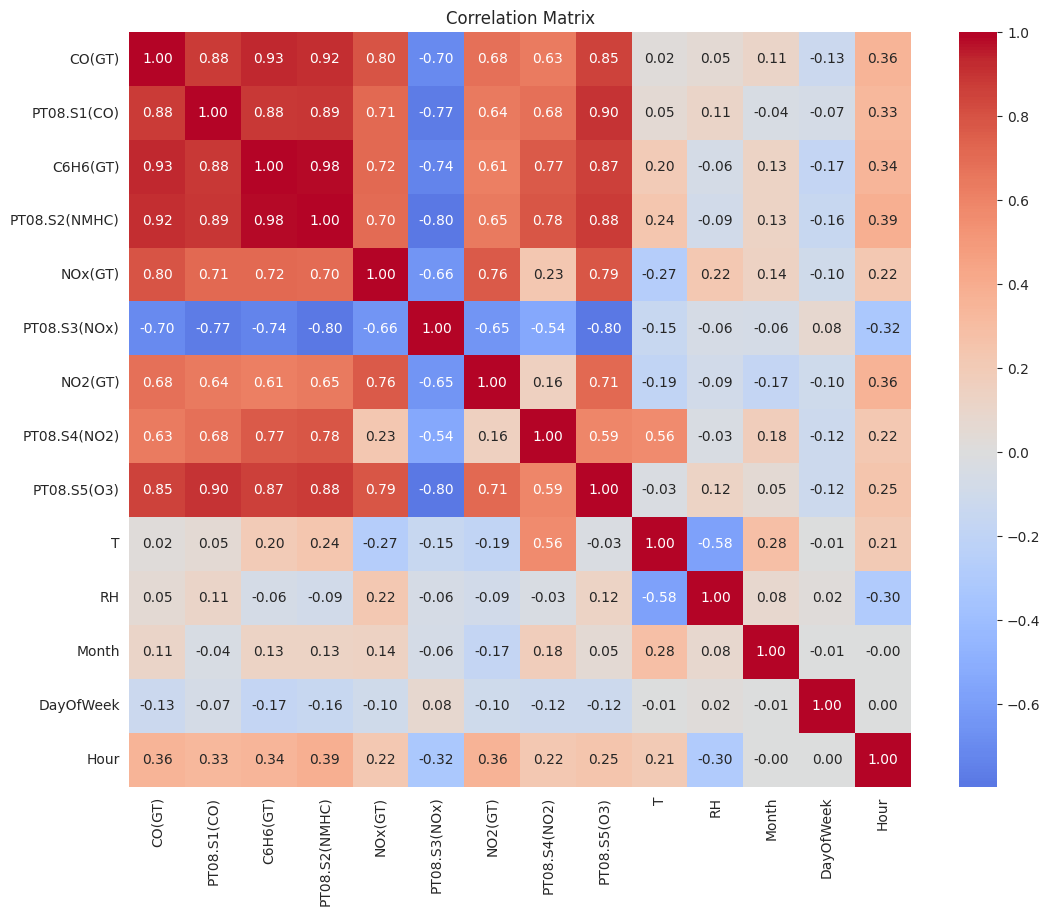

In [ ]:
numerical_cols   = df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in df.columns if c not in numerical_cols]

print("Numerical columns  :", numerical_cols)
print("Categorical columns:", categorical_cols if categorical_cols else "None")

print("\nNumber of unique values per column:")
display(df.nunique().to_frame("unique_values"))

# Correlation heatmap (numerical columns only)
if len(numerical_cols) >= 2:
    plt.figure(figsize=(max(5, len(numerical_cols)*0.9), max(4, len(numerical_cols)*0.7)))
    sns.heatmap(df[numerical_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Matrix")
    plt.show()
else:
    print("Not enough numerical columns for a correlation matrix.")

### 4.2 Histograms
Histograms show the shape of every numerical column. A high skew value (|skew| > 1) means a long tail, which is one reason we cap outliers and scale the features later.

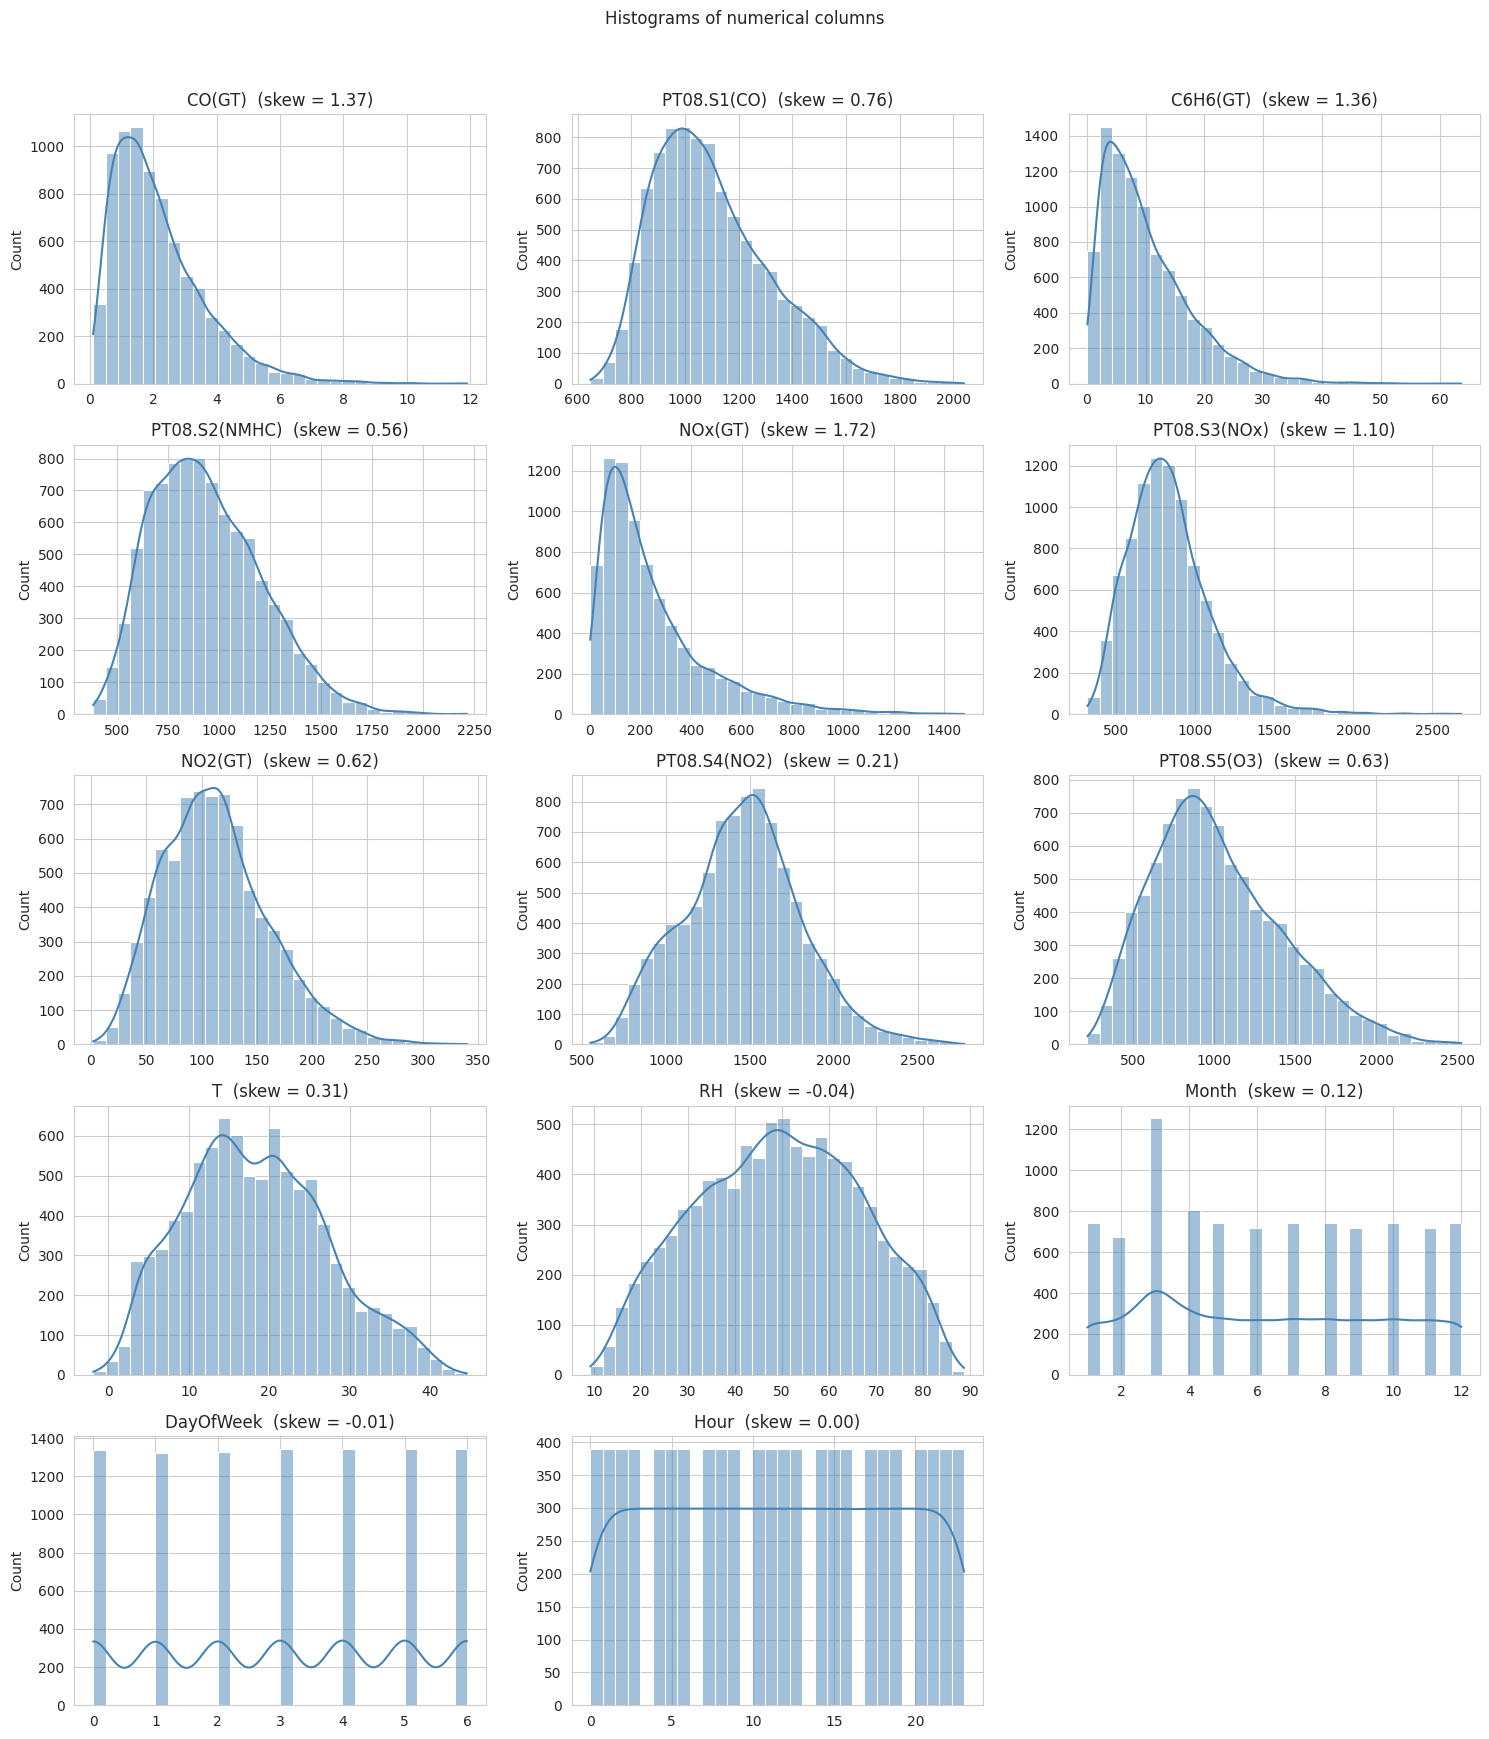

In [ ]:
eda_cols = df.select_dtypes(include="number").columns.tolist()
eda_target = TARGET_COLUMN if TARGET_COLUMN in df.columns else eda_cols[-1]

n_cols = 3
n_rows = int(np.ceil(len(eda_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.4 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, eda_cols):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.set_xlabel("")
for ax in axes[len(eda_cols):]:
    ax.axis("off")
plt.suptitle("Histograms of numerical columns", y=1.02)
plt.tight_layout()
plt.show()

### 4.3 Target distribution / class distribution
Because this is regression, the target has no classes. Instead we check the **distribution of the target** (is it skewed? are there extreme values?) and the **count plots of discrete features** (Month, DayOfWeek, Hour) to see whether the data is spread evenly over time.

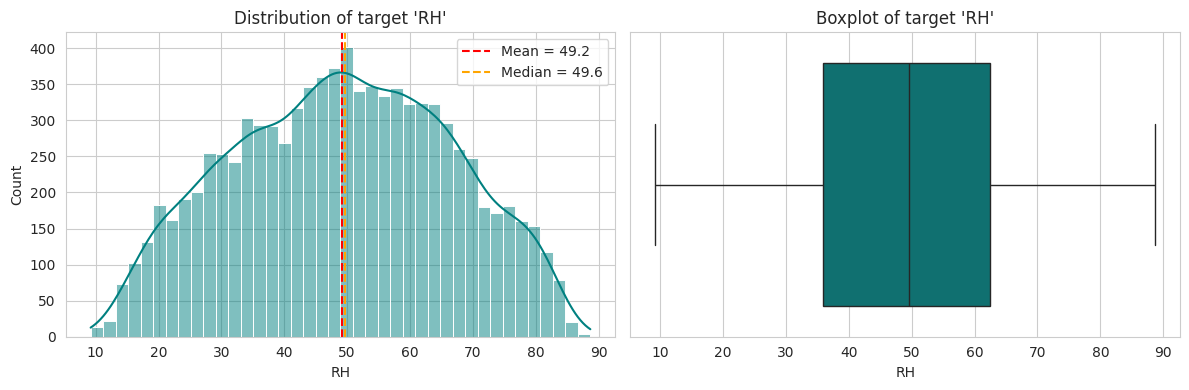

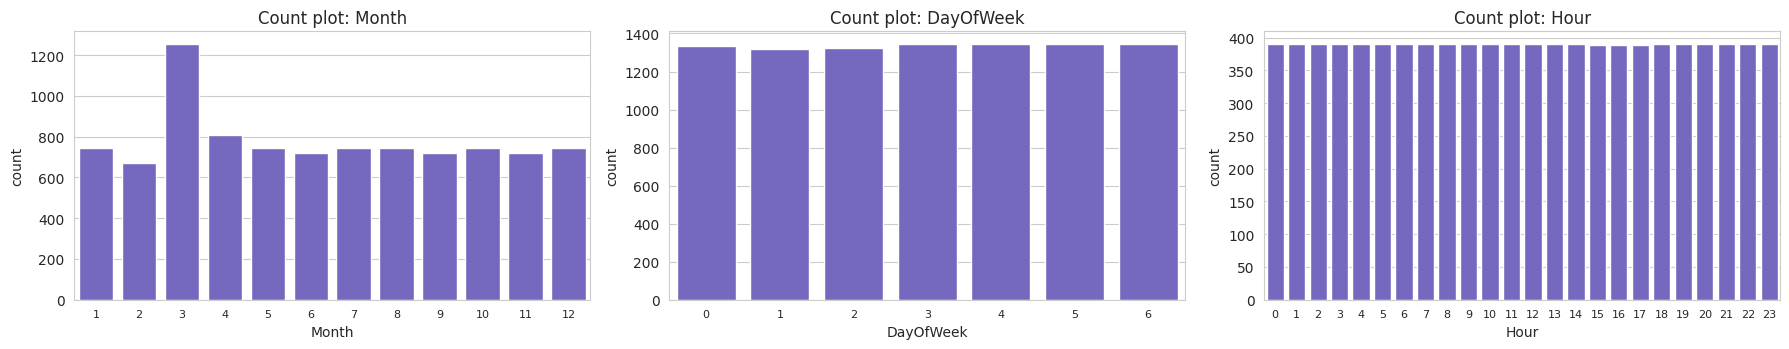

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t = df[eda_target].dropna()
sns.histplot(t, bins=40, kde=True, ax=axes[0], color="teal")
axes[0].axvline(t.mean(),   color="red",    linestyle="--", label=f"Mean = {t.mean():.1f}")
axes[0].axvline(t.median(), color="orange", linestyle="--", label=f"Median = {t.median():.1f}")
axes[0].set_title(f"Distribution of target '{eda_target}'")
axes[0].legend()
sns.boxplot(x=t, ax=axes[1], color="teal")
axes[1].set_title(f"Boxplot of target '{eda_target}'")
plt.tight_layout()
plt.show()

# Count plots for categorical / discrete columns
discrete_cols = [c for c in df.columns if c != eda_target and (c in categorical_cols or df[c].nunique() <= 31)]
if discrete_cols:
    fig, axes = plt.subplots(1, len(discrete_cols), figsize=(6 * len(discrete_cols), 3.6))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, discrete_cols):
        sns.countplot(x=df[col], ax=ax, color="slateblue")
        ax.set_title(f"Count plot: {col}")
        ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("No categorical / discrete columns to plot.")

### 4.4 Scatter plots (top features vs target)
The six numerical features most correlated (in absolute value) with the target are plotted against it, with a red trend line. A curved cloud of points suggests that Polynomial Regression may fit better than a straight line.

Top features by |correlation| with target: ['T', 'Hour', 'NOx(GT)', 'PT08.S5(O3)', 'PT08.S1(CO)', 'NO2(GT)']


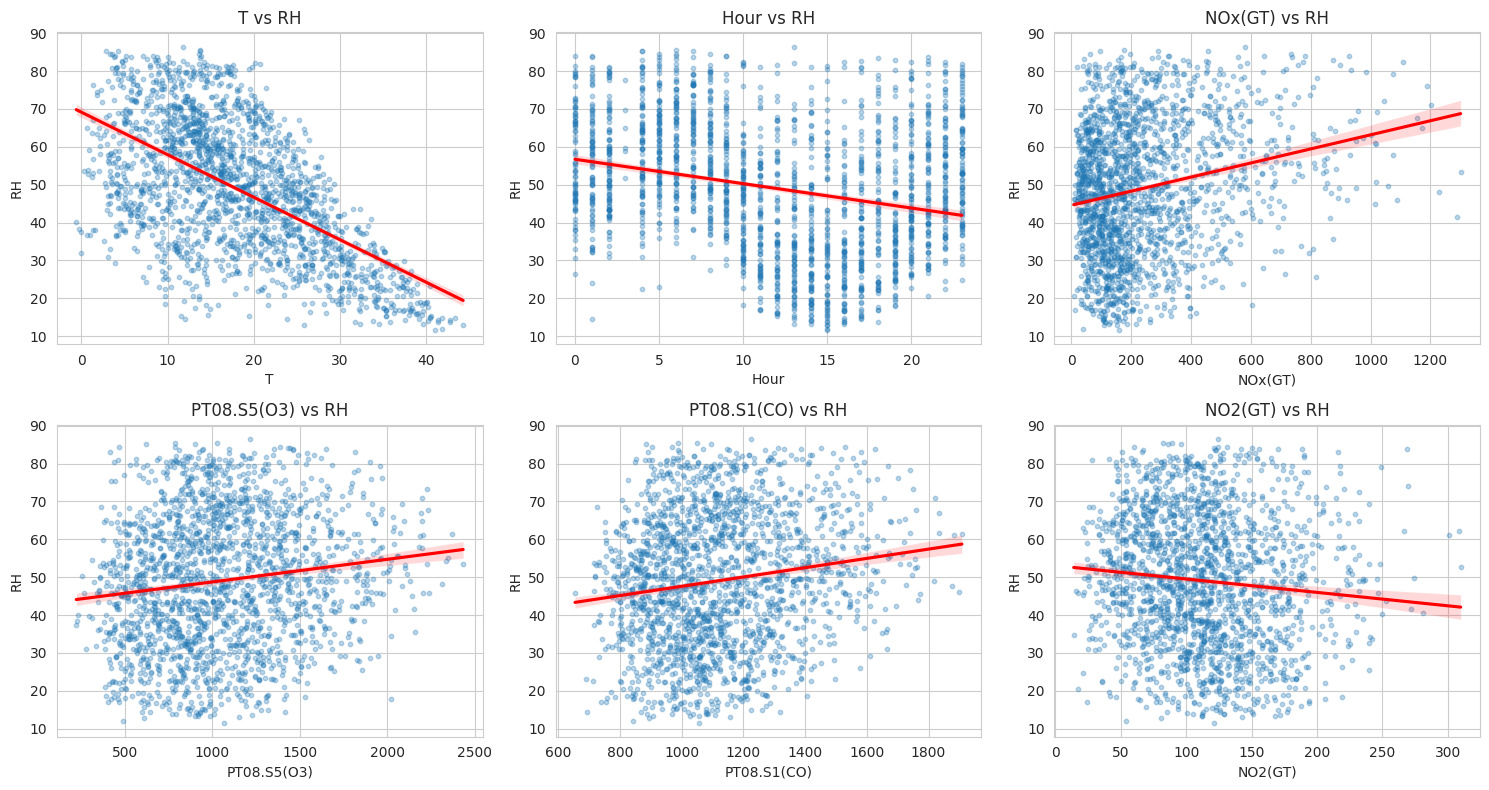

In [ ]:
corr_abs = df[eda_cols].corr()[eda_target].drop(eda_target).abs().sort_values(ascending=False)
top_feats = corr_abs.head(6).index.tolist()
print("Top features by |correlation| with target:", top_feats)

plot_df = df[top_feats + [eda_target]].dropna()
plot_df = plot_df.sample(min(2000, len(plot_df)), random_state=RANDOM_STATE)   # sample keeps the plots fast

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.reshape(-1), top_feats):
    sns.regplot(data=plot_df, x=col, y=eda_target, ax=ax,
                scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
    ax.set_title(f"{col} vs {eda_target}")
for ax in axes.reshape(-1)[len(top_feats):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.5 Pair plot
A pair plot shows every pairwise relationship at once. To keep it readable and fast, only the **top 4 features + the target** and a random sample of 500 rows are used.

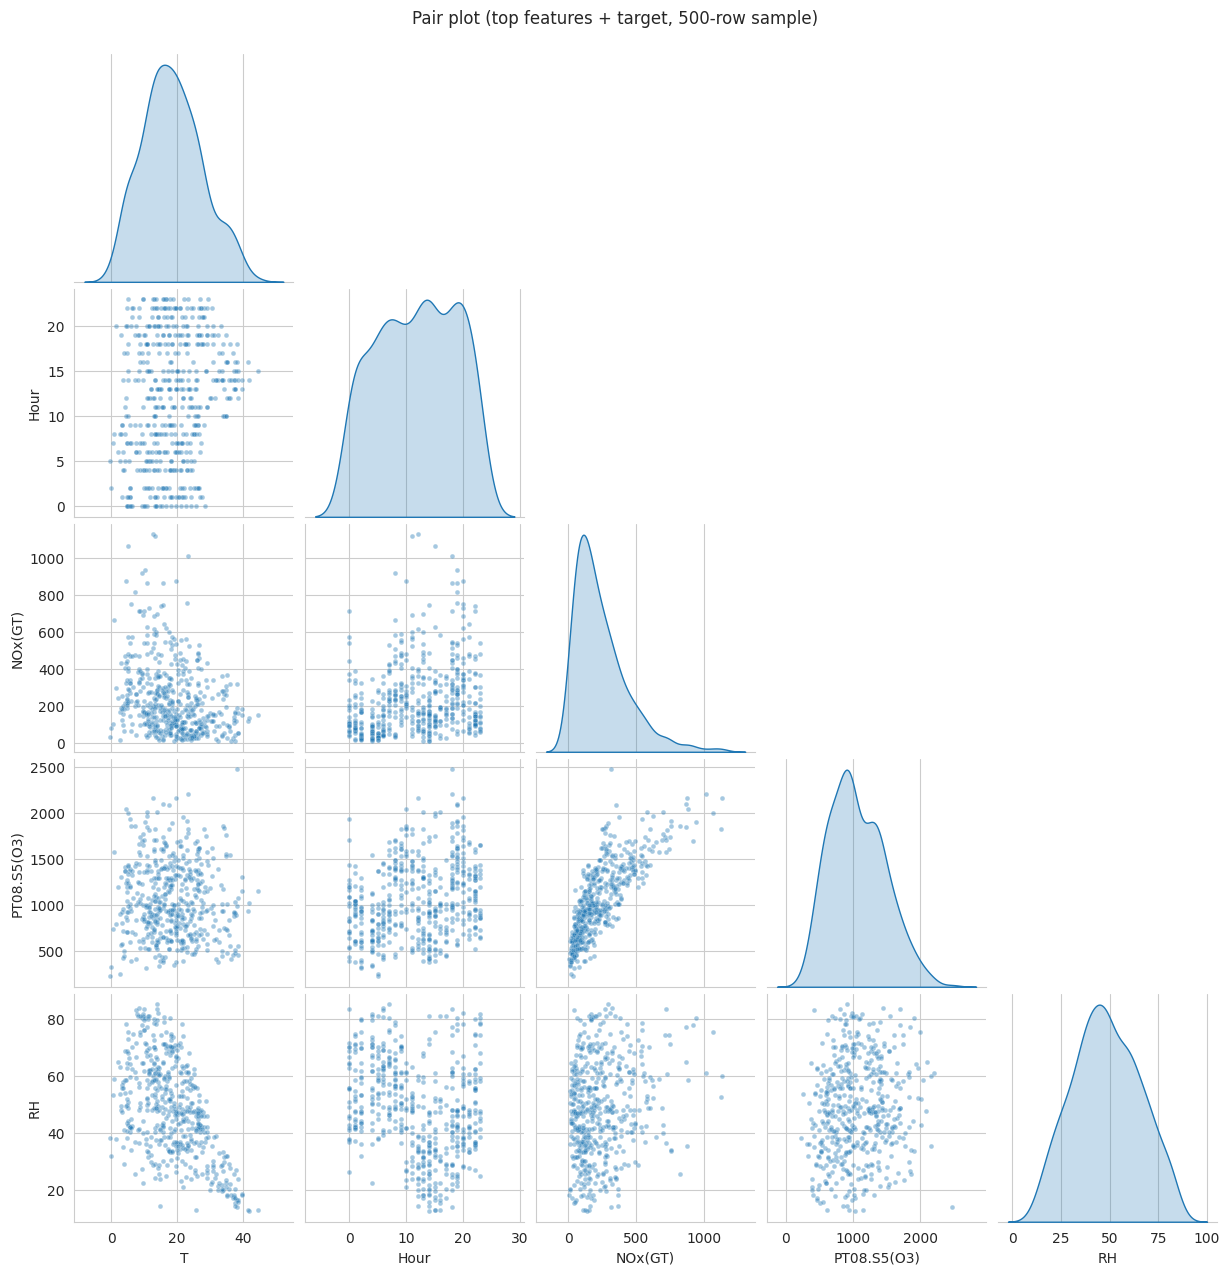

In [ ]:
pair_cols = top_feats[:4] + [eda_target]
pair_df = df[pair_cols].dropna()
pair_df = pair_df.sample(min(500, len(pair_df)), random_state=RANDOM_STATE)
g = sns.pairplot(pair_df, corner=True, diag_kind="kde", plot_kws={"alpha": 0.4, "s": 12})
g.fig.suptitle("Pair plot (top features + target, 500-row sample)", y=1.02)
plt.show()

## 5. Missing Value Analysis & Handling
**Detect now, fix later (inside the pipeline).** Filling missing values uses statistics (e.g. the median) calculated from the data. If we calculated them on the *whole* dataset, information from the test set would leak into training. So here we only *report* missing values; the actual filling happens in Section 10 and is learned from the **training set only**.

**Strategy used:**
- Numerical columns → **median** (not affected by outliers, unlike the mean).
- Categorical columns → **most frequent value**.
- Rows where the **target** is missing are dropped (we cannot train or test on an unknown answer).

In [ ]:
missing_count = df.isnull().sum()
missing_pct   = (missing_count / len(df) * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing_count, "missing_%": missing_pct})
total_missing = int(missing_count.sum())

if total_missing == 0:
    print("No missing values found.")
else:
    print(f"Total missing values: {total_missing}")
    display(missing_table[missing_table["missing_count"] > 0])
    print("They will be filled inside the pipeline (median for numbers, most frequent for categories).")

Total missing values: 7892


,missing_count,missing_%
CO(GT),1683,17.99
PT08.S1(CO),366,3.91
C6H6(GT),366,3.91
PT08.S2(NMHC),366,3.91
NOx(GT),1639,17.52
PT08.S3(NOx),366,3.91
NO2(GT),1642,17.55
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91
T,366,3.91


They will be filled inside the pipeline (median for numbers, most frequent for categories).


**Visual check of missing values** – the bar chart shows how much is missing per column; in the heatmap each white line is a missing value (rows = observations).

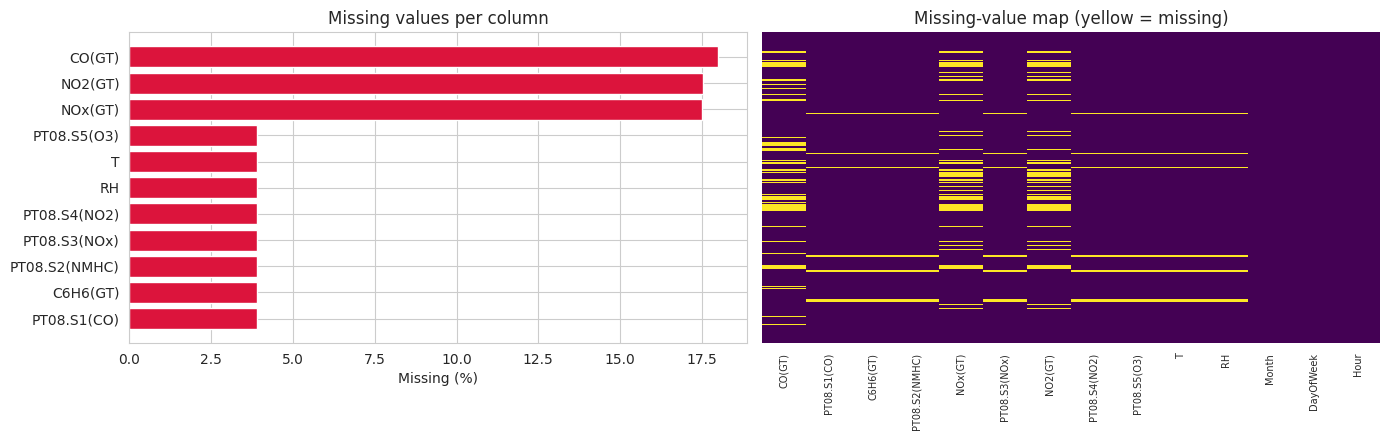

In [ ]:
miss_plot = missing_table[missing_table["missing_count"] > 0].sort_values("missing_%")
if len(miss_plot):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].barh(miss_plot.index, miss_plot["missing_%"], color="crimson")
    axes[0].set_xlabel("Missing (%)")
    axes[0].set_title("Missing values per column")
    sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
    axes[1].set_title("Missing-value map (yellow = missing)")
    axes[1].tick_params(axis="x", labelsize=7)
    plt.tight_layout()
    plt.show()
else:
    print("Nothing to plot: no missing values.")

## 6. Duplicate Detection & Handling
Exact duplicate rows add no new information and can leak between train and test (the same row appearing in both sets makes results look better than they are). We remove them **before** splitting.

In [ ]:
duplicate_count = int(df.duplicated().sum())
print("Shape before duplicate removal:", df.shape)

if duplicate_count == 0:
    print("No duplicate rows found.")
else:
    print(f"Duplicate rows found: {duplicate_count}")
    df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal :", df.shape)

Shape before duplicate removal: (9357, 14)
No duplicate rows found.
Shape after duplicate removal : (9357, 14)


## 7. Outlier Detection & Handling
**Detection (IQR rule):** a value is an outlier if it is below `Q1 − 1.5×IQR` or above `Q3 + 1.5×IQR`.

**Handling strategy (safe, not blind deletion):**
- **Never delete rows automatically.** Outliers are often real, valid values, and small class datasets can't afford to lose rows.
- **Cap (winsorize)** extreme *feature* values to the IQR limits — this reduces their pull on the model. The limits are learned from the **training data only** inside the pipeline (Section 10).
- **The target column is never capped or changed.**
- If you know an outlier is a typing mistake, fix or remove it manually. If it's real and important, use `OUTLIER_STRATEGY = "keep"`.
- Tree-based models are not sensitive to outliers; Linear Regression is.

Total outlier values detected: 1602


,column,lower_bound,upper_bound,outliers,outliers_%
0,CO(GT),-1.60,5.60,215,2.80
1,PT08.S1(CO),496.00,1672.00,118,1.31
2,C6H6(GT),-10.00,28.40,228,2.54
3,PT08.S2(NMHC),162.25,1688.25,65,0.72
4,NOx(GT),-244.00,668.00,435,5.64
5,PT08.S3(NOx),190.75,1436.75,241,2.68
6,NO2(GT),-18.00,238.00,107,1.39
7,PT08.S4(NO2),556.50,2344.50,97,1.08
8,PT08.S5(O3),-81.50,2086.50,93,1.03
9,T,-7.10,43.30,3,0.03


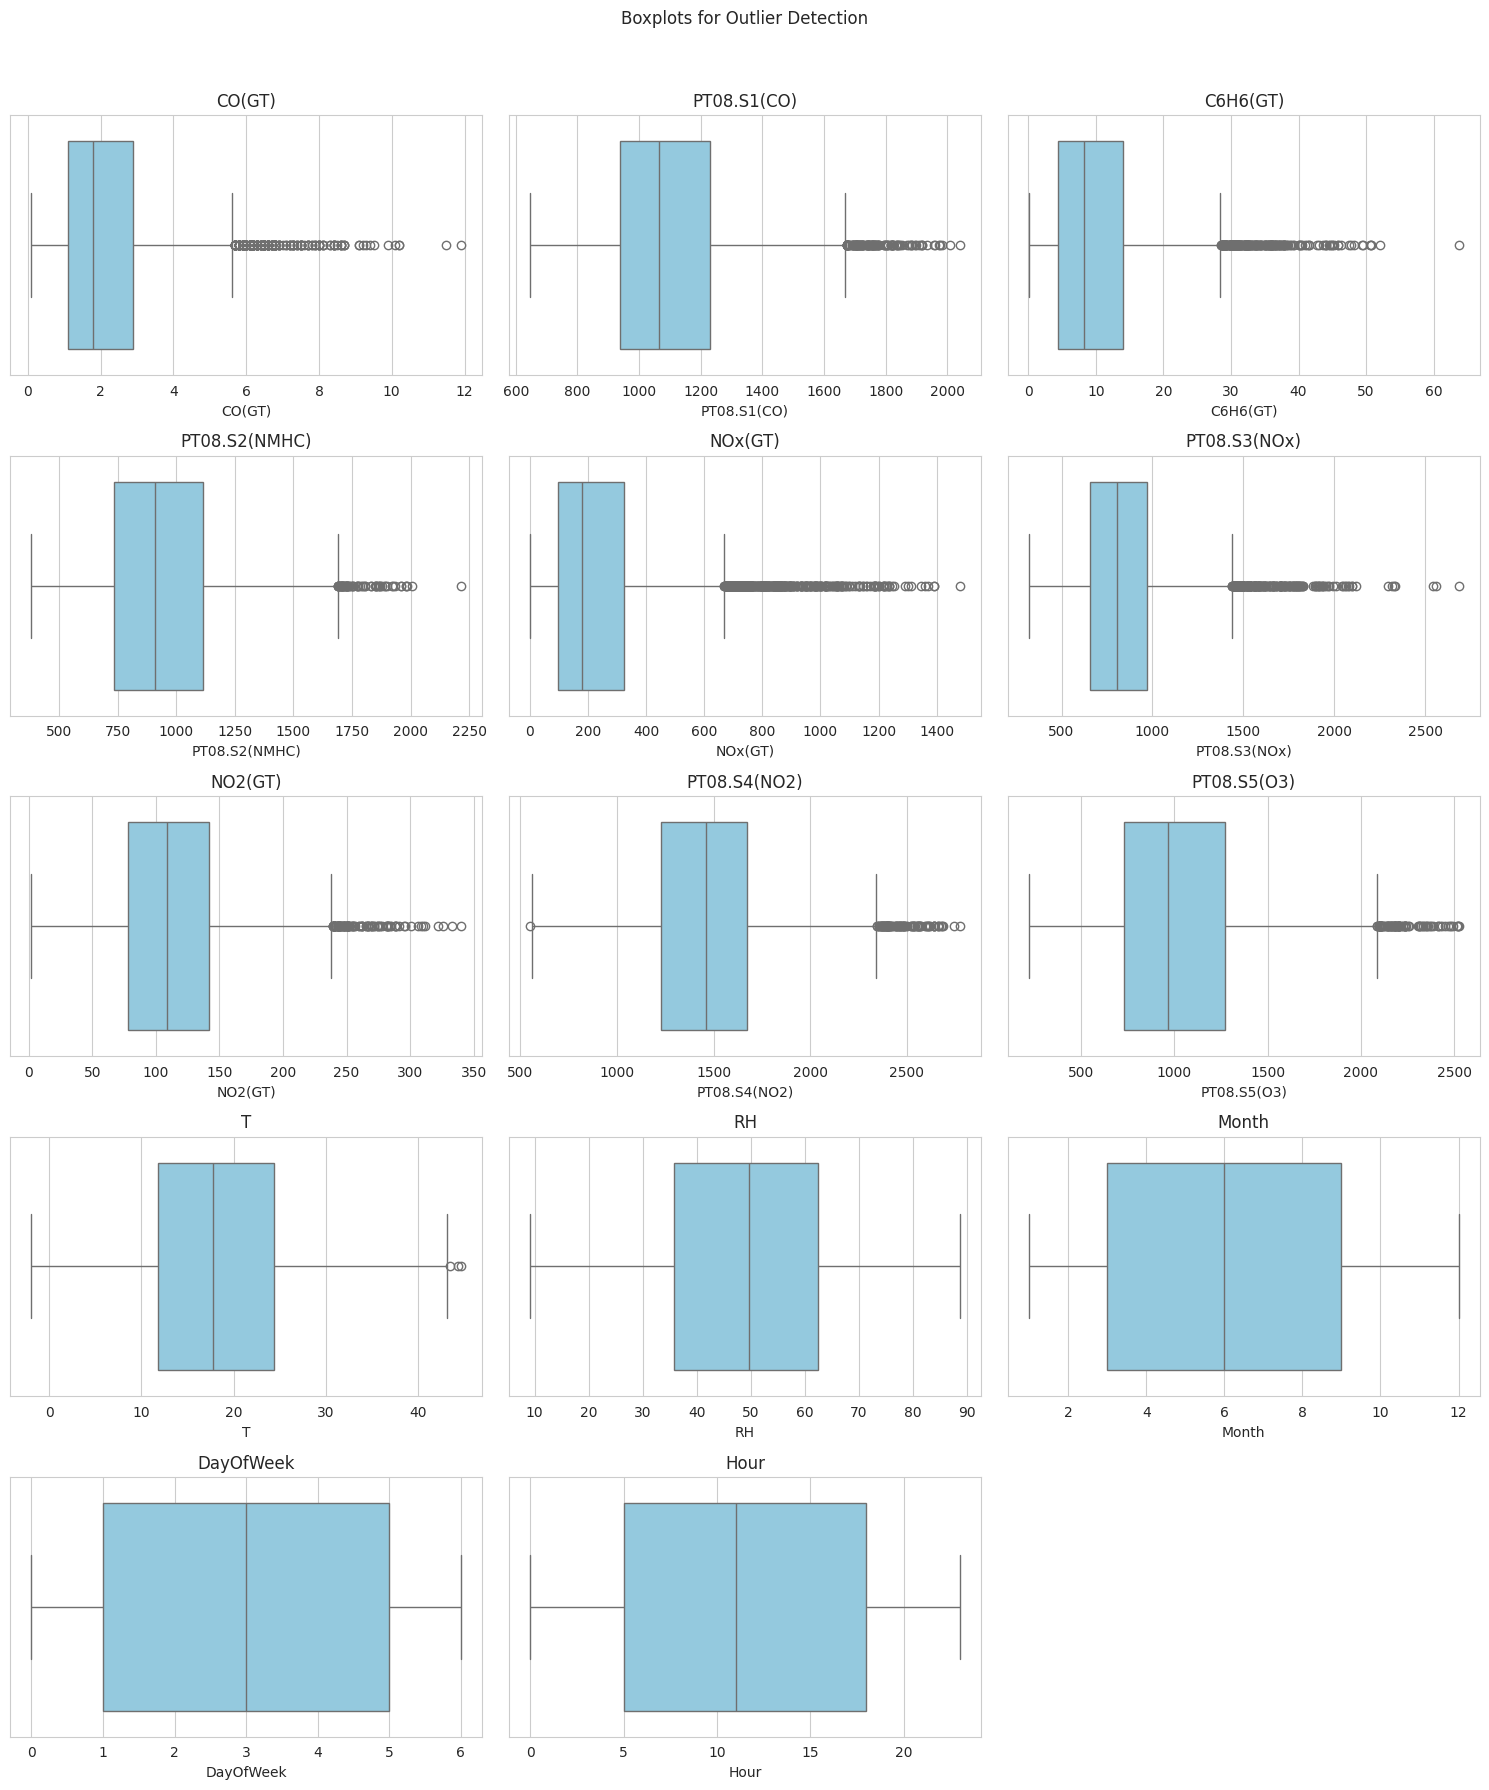

Strategy: feature outliers will be CAPPED inside the pipeline (limits learned from training data only).


In [ ]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()

def iqr_bounds(series, factor=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - factor * iqr, q3 + factor * iqr

rows = []
for col in numerical_cols:
    s = df[col].dropna()
    low, high = iqr_bounds(s)
    n_out = int(((s < low) | (s > high)).sum())
    rows.append({"column": col, "lower_bound": round(low, 3), "upper_bound": round(high, 3),
                 "outliers": n_out, "outliers_%": round(n_out / max(len(s), 1) * 100, 2)})

outlier_table = pd.DataFrame(rows)
total_outliers = int(outlier_table["outliers"].sum()) if len(rows) else 0

if total_outliers == 0:
    print("No outliers detected (IQR method).")
else:
    print(f"Total outlier values detected: {total_outliers}")
display(outlier_table)

# Boxplots
if numerical_cols:
    n_cols = 3
    n_rows = int(np.ceil(len(numerical_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 3.5*n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, numerical_cols):
        sns.boxplot(x=df[col], ax=ax, color="skyblue")
        ax.set_title(col)
    for ax in axes[len(numerical_cols):]:
        ax.axis("off")
    plt.suptitle("Boxplots for Outlier Detection", y=1.02)
    plt.tight_layout()
    plt.show()

if OUTLIER_STRATEGY == "cap":
    print("Strategy: feature outliers will be CAPPED inside the pipeline (limits learned from training data only).")
else:
    print("Strategy: outliers are KEPT as they are.")

## 8. Target & Feature Selection
The target (`y`) is what we predict; the features (`X`) are everything else. If `TARGET_COLUMN` is `None`, the notebook suggests the **last numerical column** (a common convention). The target must be numeric for regression.

Dropped 366 row(s) with missing target.
Target column        : RH
Number of features   : 13
Numerical features   : ['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'Month', 'DayOfWeek', 'Hour']
Categorical features : None


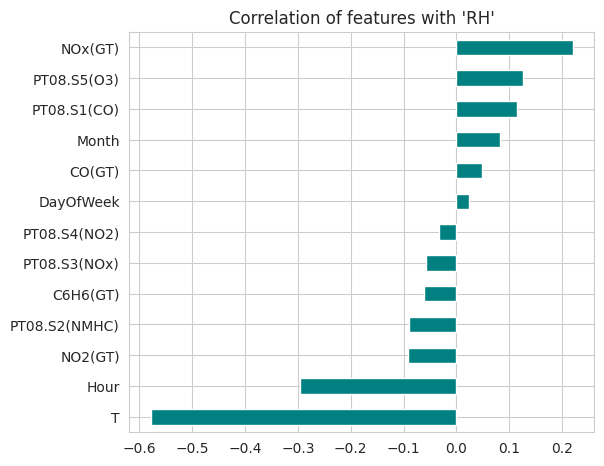

In [ ]:
numeric_candidates = df.select_dtypes(include="number").columns.tolist()
suggested_target = numeric_candidates[-1] if numeric_candidates else None

if TARGET_COLUMN is None:
    TARGET_COLUMN = suggested_target
    print(f"No target given. Auto-suggested target: '{TARGET_COLUMN}'")

# ---- Validation with clear messages ----
if TARGET_COLUMN not in df.columns:
    raise ValueError(f"Target column '{TARGET_COLUMN}' was not found.\n"
                     f"Available columns: {list(df.columns)}\n"
                     f"Suggestion: TARGET_COLUMN = \"{suggested_target}\"")

if not pd.api.types.is_numeric_dtype(df[TARGET_COLUMN]):
    raise ValueError(f"Target column '{TARGET_COLUMN}' is not numeric, so regression cannot be used.\n"
                     f"Numeric columns you could use: {numeric_candidates}")

# Drop rows where the target is missing
n_before = len(df)
df = df.dropna(subset=[TARGET_COLUMN]).reset_index(drop=True)
if len(df) < n_before:
    print(f"Dropped {n_before - len(df)} row(s) with missing target.")

# ---- Separate X and y ----
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

# Optional: treat chosen numeric columns as categories (they will be One-Hot encoded in the pipeline)
for c in ENCODE_AS_CATEGORICAL:
    if c in X.columns:
        X[c] = X[c].apply(lambda v: str(int(v)) if pd.notna(v) else np.nan)
        print(f"'{c}' converted to a categorical column.")

# Drop columns that are completely empty (nothing to learn from them)
empty_cols = [c for c in X.columns if X[c].isnull().all()]
if empty_cols:
    print("Dropping completely empty columns:", empty_cols)
    X = X.drop(columns=empty_cols)

if X.shape[1] == 0:
    raise ValueError("No feature columns left. The dataset needs at least one column besides the target.")

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = [c for c in X.columns if c not in num_features]

print("Target column        :", TARGET_COLUMN)
print("Number of features   :", X.shape[1])
print("Numerical features   :", num_features)
print("Categorical features :", cat_features if cat_features else "None")

# Correlation of each numeric feature with the target
if num_features:
    corr_target = df[num_features + [TARGET_COLUMN]].corr()[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values()
    corr_target.plot(kind="barh", figsize=(6, max(2, 0.4*len(corr_target))), color="teal")
    plt.title(f"Correlation of features with '{TARGET_COLUMN}'")
    plt.show()

## 9. Train-Test Split
We split the data into a **training set** (the model learns from it) and a **test set** (kept hidden to measure how well the model works on *new* data). Without this, we couldn't tell a model that truly learned from one that just memorised the data. `random_state` makes the split identical every time.

> ⚠️ **Data leakage rule:** we split *before* any imputing, scaling or encoding.

In [ ]:
if len(X) < 10:
    print(f"Warning: only {len(X)} rows. Results will be unstable with such a small dataset.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, " | Test set:", X_test.shape)
if len(X_test) < 2:
    print("Warning: fewer than 2 test rows, so R² cannot be computed reliably.")

Training set: (7192, 13)  | Test set: (1799, 13)


## 10. Preprocessing Pipeline (No Data Leakage)
**Why this matters:** steps like the median, IQR limits, scaler mean/std and one-hot categories are *learned from data*. If they were learned from the full dataset, the test set would secretly influence training and the scores would look better than reality (**data leakage**).

Using `Pipeline` + `ColumnTransformer`, all of these are `fit` on **training data only**, and then merely *applied* to the test data.

> This dataset has **no text (categorical) columns**, so the One-Hot branch is empty by default. It is fully built and switches on automatically if the data contains text columns or if you list columns in `ENCODE_AS_CATEGORICAL`.

| Column type | Steps |
|---|---|
| Numerical | Median imputation → IQR outlier capping (optional) → StandardScaler |
| Categorical | Most-frequent imputation → One-Hot Encoding |

In [ ]:
class IQRCapper(BaseEstimator, TransformerMixin):
    """Caps values to [Q1 - k*IQR, Q3 + k*IQR]. Limits are learned in fit() (training data only)."""
    def __init__(self, factor=1.5):
        self.factor = factor
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

# Numerical pipeline
num_steps = [("imputer", SimpleImputer(strategy="median"))]
if OUTLIER_STRATEGY == "cap":
    num_steps.append(("outlier_cap", IQRCapper(factor=1.5)))
num_steps.append(("scaler", StandardScaler()))
num_pipeline = Pipeline(num_steps)

# Categorical pipeline (works across sklearn versions)
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", encoder),
])

# Combine only the column groups that exist
transformers = []
if num_features:
    transformers.append(("num", num_pipeline, num_features))
if cat_features:
    transformers.append(("cat", cat_pipeline, cat_features))
preprocessor = ColumnTransformer(transformers)

print("Preprocessing pipeline created.")
print("Numerical features :", len(num_features), "| Categorical features:", len(cat_features))

Preprocessing pipeline created.
Numerical features : 13 | Categorical features: 0


### 10.1 Check what the pipeline does (scaling + outlier capping)
The pipeline is fitted on the **training set only** and applied to it here purely for inspection. After `StandardScaler` every numerical feature should have **mean ≈ 0 and std ≈ 1**. The boxplots compare the standardised raw features with the capped + standardised ones: the extreme points beyond the whiskers are pulled in when `OUTLIER_STRATEGY = "cap"`.

Shape before preprocessing: (7192, 13)  | after: (7192, 13)
Missing values left after preprocessing: 0


,mean,std,min,max
num__CO(GT),0.0,1.0,-1.725,2.247
num__PT08.S1(CO),0.0,1.0,-2.107,2.679
num__C6H6(GT),-0.0,1.0,-1.416,2.627
num__PT08.S2(NMHC),-0.0,1.0,-2.095,2.824
num__NOx(GT),0.0,1.0,-1.473,2.211
num__PT08.S3(NOx),0.0,1.0,-2.135,2.552
num__NO2(GT),0.0,1.0,-2.383,2.254
num__PT08.S4(NO2),0.0,1.0,-2.613,2.583
num__PT08.S5(O3),-0.0,1.0,-2.018,2.708
num__T,0.0,1.0,-2.294,2.827


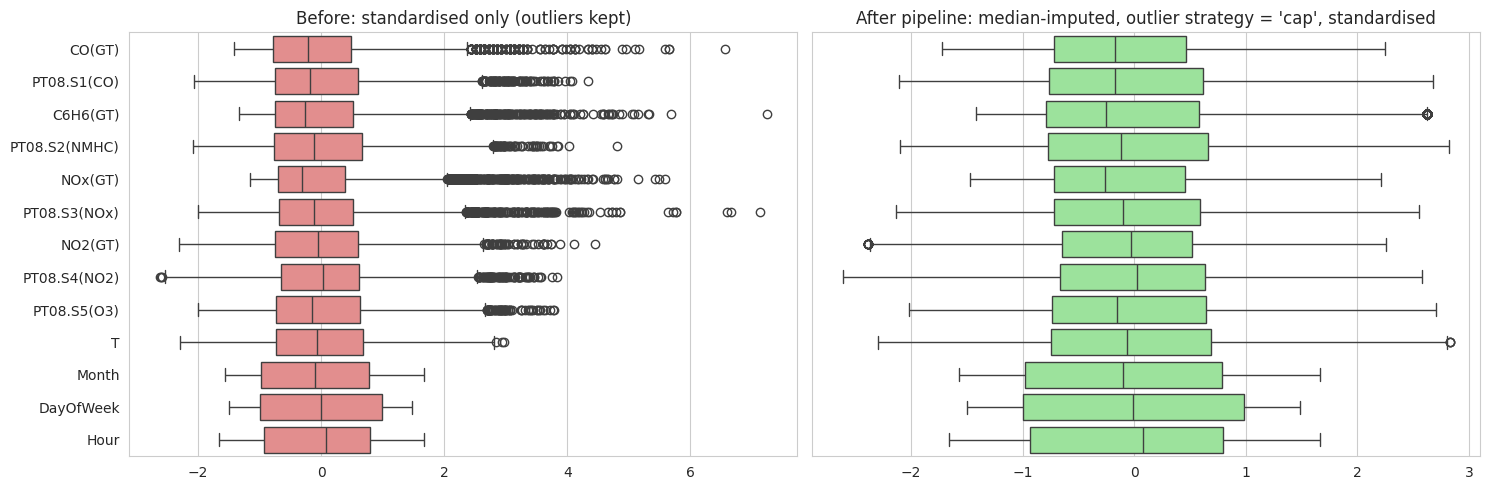

In [ ]:
from sklearn.base import clone

_prep = clone(preprocessor).fit(X_train)
_arr  = _prep.transform(X_train)
try:
    _names = list(_prep.get_feature_names_out())
except Exception:
    _names = [f"f{k}" for k in range(_arr.shape[1])]
X_train_prep = pd.DataFrame(_arr, columns=_names)

print("Shape before preprocessing:", X_train.shape, " | after:", X_train_prep.shape)
print("Missing values left after preprocessing:", int(X_train_prep.isnull().sum().sum()))
display(X_train_prep.describe().T[["mean", "std", "min", "max"]].round(3))

if num_features:
    raw_z  = (X_train[num_features] - X_train[num_features].mean()) / X_train[num_features].std()
    proc_z = X_train_prep.iloc[:, :len(num_features)].copy()
    proc_z.columns = num_features
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    sns.boxplot(data=raw_z, orient="h", ax=axes[0], color="lightcoral")
    axes[0].set_title("Before: standardised only (outliers kept)")
    sns.boxplot(data=proc_z, orient="h", ax=axes[1], color="lightgreen")
    axes[1].set_title(f"After pipeline: median-imputed, outlier strategy = '{OUTLIER_STRATEGY}', standardised")
    plt.tight_layout()
    plt.show()

## 11. Model Training (Linear & Polynomial Regression)
Choose the model with `MODEL_NAME` in Section 2.

- **Linear Regression:** fits a straight-line formula `y = b0 + b1·x1 + b2·x2 + …`.
- **Polynomial Regression:** first creates new features from the old ones (squares like `x1²`, and products like `x1·x2`, up to `POLY_DEGREE`), then fits a Linear Regression on them. The model is still linear in its coefficients, but the *relationship* it draws can be curved, so it can capture non-linear patterns.

The full pipeline (preprocessing → polynomial expansion → regression) is trained on the training set only. Polynomial expansion happens **after** scaling so that squared/cubed values stay in a sensible range.

In [ ]:
from sklearn.base import clone

available_models = ["Linear Regression", "Polynomial Regression"]
if MODEL_NAME not in available_models:
    raise ValueError(f"Unknown MODEL_NAME '{MODEL_NAME}'. Choose from: {available_models}")

def build_model(name, degree=POLY_DEGREE):
    steps = [("preprocessor", clone(preprocessor))]
    if name == "Polynomial Regression":
        steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
    steps.append(("model", LinearRegression()))
    return Pipeline(steps)

model = build_model(MODEL_NAME)
model.fit(X_train, y_train)      # every learned value comes from X_train only

label = MODEL_NAME + (f" (degree {POLY_DEGREE})" if MODEL_NAME == "Polynomial Regression" else "")
print(f"{label} trained on {len(X_train)} rows.")

# Number of features the model actually sees (after encoding and polynomial expansion)
n_model_features = model[:-1].transform(X_train.head(1)).shape[1]
print("Features seen by the model (after encoding / polynomial expansion):", n_model_features)

# Learned coefficients
try:
    names = model[:-1].get_feature_names_out()
    coefs = pd.Series(model.named_steps["model"].coef_, index=names)
    print("\nIntercept:", round(float(model.named_steps["model"].intercept_), 4))
    if MODEL_NAME == "Linear Regression":
        print("Coefficients (on scaled features):")
        display(coefs.sort_values().to_frame("coefficient"))
    else:
        print(f"{len(coefs)} polynomial terms. The 10 with the largest absolute coefficient:")
        display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).to_frame("coefficient"))
except Exception:
    pass

Polynomial Regression (degree 3) trained on 7192 rows.
Features seen by the model (after encoding / polynomial expansion): 559

Intercept: 44.7354
559 polynomial terms. The 10 with the largest absolute coefficient:


,coefficient
num__C6H6(GT) num__PT08.S2(NMHC)^2,60.269574
num__C6H6(GT)^2 num__PT08.S2(NMHC),-54.842283
num__PT08.S2(NMHC),-42.493917
num__C6H6(GT) num__PT08.S2(NMHC) num__PT08.S4(NO2),-29.822343
num__C6H6(GT) num__PT08.S2(NMHC) num__NO2(GT),-25.771591
num__CO(GT) num__C6H6(GT) num__PT08.S2(NMHC),25.219170
num__PT08.S1(CO) num__C6H6(GT) num__PT08.S2(NMHC),22.323377
num__PT08.S4(NO2),22.068966
num__T,-21.500870
num__PT08.S2(NMHC) num__PT08.S3(NOx) num__PT08.S4(NO2),20.902393


## 12. Prediction

In [ ]:
y_pred = model.predict(X_test)

results = pd.DataFrame({"Actual": y_test.values, "Predicted": np.round(y_pred, 3)})
results["Error"] = np.round(results["Actual"] - results["Predicted"], 3)
display(results.head(10))

,Actual,Predicted,Error
0,49.8,45.149,4.651
1,46.4,43.851,2.549
2,70.1,64.793,5.307
3,37.9,37.253,0.647
4,55.8,50.168,5.632
5,44.9,41.390,3.510
6,45.6,46.031,-0.431
7,52.6,55.348,-2.748
8,38.7,47.416,-8.716
9,40.1,43.095,-2.995


## 13. Evaluation Metrics
- **MAE** (Mean Absolute Error): the average size of the mistakes, in the same units as the target. Lower is better.
- **MSE** (Mean Squared Error): the average of the squared mistakes. Big mistakes are punished more. Lower is better.
- **RMSE** (Root MSE): the square root of MSE, so it is back in the target's units. Lower is better.
- **R² Score**: how much of the variation in the target the model explains. 1.0 = perfect, 0 = no better than always guessing the average, negative = worse than that.

In [ ]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred) if len(y_test) >= 2 else float("nan")
train_r2 = r2_score(y_train, model.predict(X_train))

print(f"Model: {MODEL_NAME}")
print("-" * 35)
print(f"MAE      : {mae:.4f}")
print(f"MSE      : {mse:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"R² (test): {r2:.4f}")
print(f"R² (train): {train_r2:.4f}")
if not np.isnan(r2) and train_r2 - r2 > 0.2:
    print("\nNote: training R² is much higher than test R² -> the model may be overfitting.")

Model: Polynomial Regression
-----------------------------------
MAE      : 2.3916
MSE      : 10.5250
RMSE     : 3.2442
R² (test): 0.9658
R² (train): 0.9742


### 13.1 Train vs Test metrics and cross-validation
- The table compares all four metrics on the training and test sets. Similar values mean the model generalises well.
- **5-fold cross-validation** repeats the whole pipeline (imputing, capping, scaling, polynomial expansion, regression) on 5 different splits. It shows whether the single train/test split was just lucky.

,MAE,MSE,RMSE,R²
Train,2.1307,7.6822,2.7717,0.9742
Test,2.3916,10.5250,3.2442,0.9658


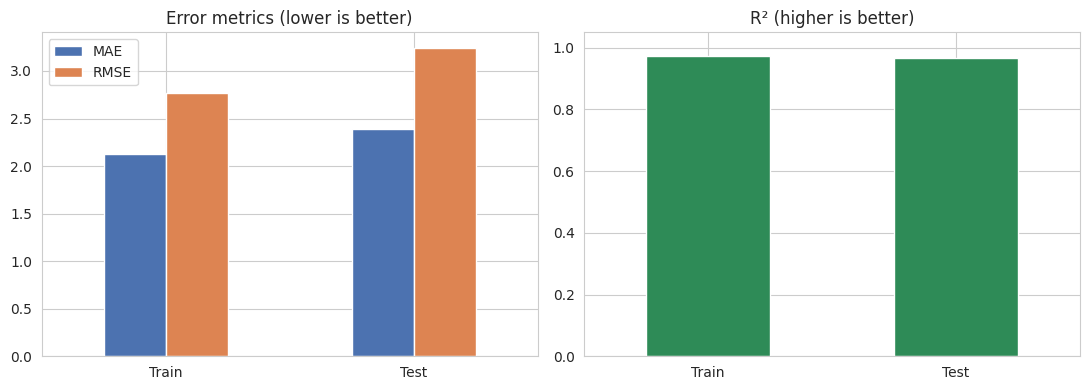

5-fold CV R² scores: [0.9658 0.967  0.9695 0.9653 0.9636]
Mean ± std         : 0.9662 ± 0.0020


In [ ]:
from sklearn.model_selection import KFold, cross_val_score

def reg_metrics(y_true, y_hat):
    m = mean_squared_error(y_true, y_hat)
    return {"MAE": mean_absolute_error(y_true, y_hat), "MSE": m, "RMSE": np.sqrt(m), "R²": r2_score(y_true, y_hat)}

metrics_df = pd.DataFrame({"Train": reg_metrics(y_train, model.predict(X_train)),
                           "Test":  reg_metrics(y_test,  y_pred)}).T
display(metrics_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metrics_df[["MAE", "RMSE"]].plot(kind="bar", ax=axes[0], rot=0, color=["#4c72b0", "#dd8452"])
axes[0].set_title("Error metrics (lower is better)")
metrics_df[["R²"]].plot(kind="bar", ax=axes[1], rot=0, color="seagreen", legend=False)
axes[1].set_ylim(0, 1.05)
axes[1].set_title("R² (higher is better)")
plt.tight_layout()
plt.show()

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(build_model(MODEL_NAME), X, y, cv=cv, scoring="r2")
print("5-fold CV R² scores:", np.round(cv_scores, 4))
print(f"Mean ± std         : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

## 14. Actual vs Predicted Visualization
Points close to the red diagonal line mean accurate predictions. The residual plot should show points scattered randomly around 0; a clear pattern suggests the model is missing something.

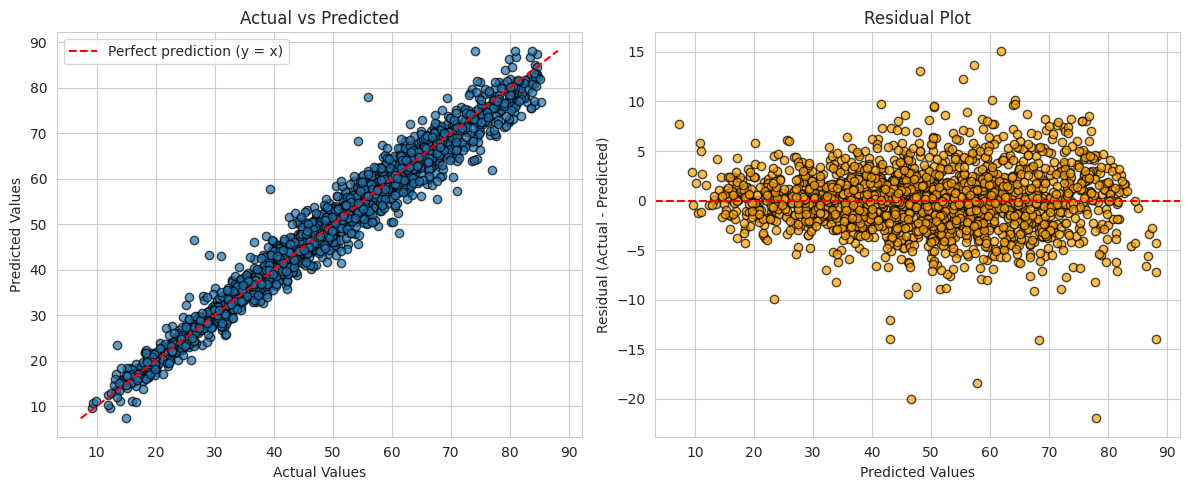

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.7, edgecolor="k")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction (y = x)")
axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")
axes[0].set_title("Actual vs Predicted")
axes[0].legend()

# Residuals
residuals = y_test.values - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.7, edgecolor="k", color="orange")
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted Values")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

### Compare Linear vs Polynomial Regression (degrees 1 to 4)
Degree 1 is ordinary Linear Regression. As the degree grows, the model fits the training data better, but at some point the test score stops improving and starts to fall. That is **overfitting**: the model memorises the training data instead of learning the real pattern. Pick the degree where the **test** R² is highest.

,Model,Degree,Features,MAE,RMSE,R² (train),R² (test)
0,Linear Regression,1,13,5.7167,7.2869,0.8300,0.8274
1,Polynomial (degree 2),2,104,3.1208,4.1672,0.9451,0.9435
2,Polynomial (degree 3),3,559,2.3916,3.2442,0.9742,0.9658
3,Polynomial (degree 4),4,2379,2.6023,4.2729,0.9893,0.9406


Best on the test set: Polynomial (degree 3)  (R² test = 0.9658)


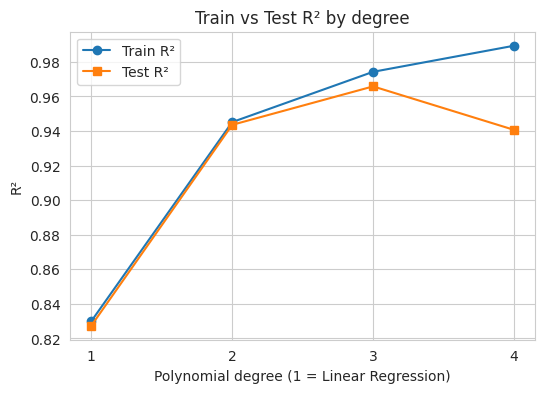

In [ ]:
comp = []
for d in [1, 2, 3, 4]:
    m = Pipeline([("preprocessor", clone(preprocessor)),
                  ("poly", PolynomialFeatures(degree=d, include_bias=False)),
                  ("model", LinearRegression())])
    m.fit(X_train, y_train)
    pr = m.predict(X_test)
    comp.append({"Model": "Linear Regression" if d == 1 else f"Polynomial (degree {d})",
                 "Degree": d,
                 "Features": m[:-1].transform(X_train.head(1)).shape[1],
                 "MAE": mean_absolute_error(y_test, pr),
                 "RMSE": np.sqrt(mean_squared_error(y_test, pr)),
                 "R² (train)": r2_score(y_train, m.predict(X_train)),
                 "R² (test)": r2_score(y_test, pr)})
comp_df = pd.DataFrame(comp)
display(comp_df.round(4))

best = comp_df.loc[comp_df["R² (test)"].idxmax()]
print(f"Best on the test set: {best['Model']}  (R² test = {best['R² (test)']:.4f})")

plt.figure(figsize=(6, 4))
plt.plot(comp_df["Degree"], comp_df["R² (train)"], "o-", label="Train R²")
plt.plot(comp_df["Degree"], comp_df["R² (test)"], "s-", label="Test R²")
plt.xticks(comp_df["Degree"])
plt.xlabel("Polynomial degree (1 = Linear Regression)")
plt.ylabel("R²")
plt.title("Train vs Test R² by degree")
plt.legend()
plt.show()

## 15. Final Summary

In [ ]:
print("=" * 50)
print("              FINAL SUMMARY")
print("=" * 50)
print(f"Dataset shape (original)      : {original_shape}")
print(f"Dataset shape (after cleaning): {df.shape}")
print(f"Columns dropped (too many NaN): {too_missing if too_missing else 'None'}")
print(f"Missing values found          : {total_missing}")
print(f"Duplicate rows found          : {duplicate_count}")
print(f"Outliers detected (IQR)       : {total_outliers}  (strategy: {OUTLIER_STRATEGY})")
print(f"Target column                 : {TARGET_COLUMN}")
print(f"Number of features            : {X.shape[1]}  ({n_model_features} after encoding/expansion)")
print(f"Model used                    : {label}")
print(f"Train / Test rows             : {len(X_train)} / {len(X_test)}")
print("-" * 50)
print(f"MAE                           : {mae:.4f}")
print(f"MSE                           : {mse:.4f}")
print(f"RMSE                          : {rmse:.4f}")
print(f"R² Score                      : {r2:.4f}")
print(f"5-fold CV R² (mean ± std)     : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print("=" * 50)

              FINAL SUMMARY
Dataset shape (original)      : (9357, 14)
Dataset shape (after cleaning): (8991, 14)
Columns dropped (too many NaN): ['NMHC(GT)']
Missing values found          : 7892
Duplicate rows found          : 0
Outliers detected (IQR)       : 1602  (strategy: cap)
Target column                 : RH
Number of features            : 13  (559 after encoding/expansion)
Model used                    : Polynomial Regression (degree 3)
Train / Test rows             : 7192 / 1799
--------------------------------------------------
MAE                           : 2.3916
MSE                           : 10.5250
RMSE                          : 3.2442
R² Score                      : 0.9658
5-fold CV R² (mean ± std)     : 0.9662 ± 0.0020
